In [1]:
import pandas as pd
import scipy.stats
from matplotlib import gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.gridspec as gridspec
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import numpy as np
from sklearn.decomposition import PCA
from collections import Counter
import torch
import os
import sys
from BWM.models.isometric_autoencoder import get_density_proxy
# Add project root to path
sys.path.append(os.path.abspath('../../'))
import torch.optim as optim
from BWM.bwm_functions import *
from BWM.models.isometric_autoencoder import SklearnIsometricAutoencoder

plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

# Set global plotting parameters for font size
tick_fontsize = 6
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': tick_fontsize,
    'ytick.labelsize': tick_fontsize,
    'legend.fontsize': 7,
    'figure.titlesize': 7
})

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


Using device: cpu


In [2]:
directory_path = '../Data2'
all_items = os.listdir(directory_path)
eids = [item for item in all_items if os.path.isdir(os.path.join(directory_path, item))]


In [4]:
from scipy.linalg import expm
def generate_constrained_orthogonal_matrix(n, epsilon):
    """
    Generates a random orthogonal matrix Q of shape (n, n) whose
    distance from the Identity matrix is scaled by epsilon.

    Parameters:
    -----------
    n : int
        The dimension of the matrix (n x n).
    epsilon : float
        Distance parameter (epsilon >= 0).
        0 yields exactly the Identity matrix.
        Small values yield matrices very close to Identity.
        Large values yield highly randomized rotations.

    Returns:
    --------
    Q : ndarray of shape (n, n)
        A random orthogonal matrix.
    """
    if epsilon < 0:
        raise ValueError("Epsilon must be greater than or equal to 0.")

    # 1. Generate a raw random matrix
    A_raw = np.random.randn(n, n)

    # 2. Make it skew-symmetric: A = A_raw - A_raw^T
    # This guarantees that A^T = -A
    A_skew = A_raw - A_raw.T

    # 3. Normalize the matrix norm so epsilon has a predictable scaling effect
    # We use the Frobenius norm to normalize the matrix scale
    norm = np.linalg.norm(A_skew, ord='fro')
    if norm > 0:
        A_skew = A_skew / norm

    # 4. Scale by our epsilon distance parameter
    A_scaled = epsilon * A_skew

    # 5. Project onto the Orthogonal Group using the Matrix Exponential
    Q = expm(A_scaled)

    return Q

def get_p(X,density,msd):

    r,_ = scipy.stats.spearmanr(msd, density)
    coeffs = []
    for i in range(3000):
        #Q =scipy.stats.ortho_group.rvs(X.shape[1])
        Q = generate_constrained_orthogonal_matrix(X.shape[1], 2)
        rotated_X = X @ Q

        diff_responses = np.diff(rotated_X, axis=1)
        msd_rotated = np.mean(np.abs(diff_responses), 1)
        coeff,_ = scipy.stats.spearmanr(msd_rotated, density)
        coeffs.append(coeff)
    coeffs = np.asarray(coeffs)

    return np.sum(coeffs>r)/len(coeffs)

def iso_ae_preprocessing(pseudo_response_tensor):
    """
    Preprocess neural responses intro response matrix (n x kt) for autoencoder.
    """
    response_tensor = np.mean(pseudo_response_tensor, axis=0)
    # Z-score and reshape
    response_tensor_norm = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    response_matrix = response_tensor_norm.reshape(-1, response_tensor_norm.shape[2])
    X_transposed = response_matrix.T
    # Scale each row (neuron) to unit length
    row_norms = np.linalg.norm(X_transposed, axis=1, keepdims=True)
    X_pre_pca = X_transposed / (row_norms + 1e-8)
    return X_pre_pca

def calculate_msd_data(response_tensor):
    """
    Calculate Mean Standardized Derivative using finite differences.
    responses: (conditions, time, neurons)
    """
    response_tensor_norm = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    diff_responses = np.diff(response_tensor_norm, axis=1)
    # Absolute standardized derivative (already standardized in the previous cell)
    # Mean over conditions and time and pseudo trials

    msd = np.mean(np.abs(diff_responses), axis=(0,1))
    return msd




In [3]:
# for region in ['CP','MOp','MRN','LD','GRN','VISp']:
region = "ORBvl"
pseudo_response_tensor, condition_matrix, neuron_eids = get_region_response_matrix(
    eids=eids,
    directory_path=directory_path,
    region=region,
    mapping='Beryl',
    sigma=2,
    n_steps=100,
    threshold=1,
    min_trials_per_condition=50,
    n_pseudo=25,
    conditions=['choice'],
    event="stimOn_times",
    filter_significant=True,
    significance_threshold=0.
)
np.save('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/ResponseData/' + region + '_pseudo_responses.npy',pseudo_response_tensor)

Aggregating ORBvl responses across 459 EIDs using 4 jobs...


Dispatching jobs:   3%|▎         | 16/459 [00:09<03:34,  2.06it/s]/Users/cl1704/anaconda3/envs/embedding_env/lib/python3.9/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
Dispatching jobs: 100%|██████████| 459/459 [03:34<00:00,  2.14it/s]


Max conditions: 2, Common conditions found: [(np.float32(-1.0),), (np.float32(1.0),)]
Total neurons collected: 2046


In [95]:




CP_responses = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/ResponseData/CP_pseudo_responses.npy')
MOp_responses = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/ResponseData/MOp_pseudo_responses.npy')
MRN_responses = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/ResponseData/MRN_pseudo_responses.npy')
LD_responses = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/ResponseData/LD_pseudo_responses.npy')
GRN_responses = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/ResponseData/GRN_pseudo_responses.npy')
VISp_responses = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/ResponseData/VISp_pseudo_responses.npy')

X_CP = iso_ae_preprocessing(CP_responses)
X_MOp = iso_ae_preprocessing(MOp_responses)
X_MRN = iso_ae_preprocessing(MRN_responses)
X_LD = iso_ae_preprocessing(LD_responses)
X_GRN = iso_ae_preprocessing(GRN_responses)
X_VISp = iso_ae_preprocessing(VISp_responses)

msd_CP = calculate_msd_data(np.mean(CP_responses, axis=0))
msd_MOp = calculate_msd_data(np.mean(MOp_responses, axis=0))
msd_MRN = calculate_msd_data(np.mean(MRN_responses, axis=0))
msd_LD = calculate_msd_data(np.mean(LD_responses, axis=0))
msd_GRN = calculate_msd_data(np.mean(GRN_responses, axis=0))
msd_VISp = calculate_msd_data(np.mean(VISp_responses, axis=0))

z_neurons_CP = umap.UMAP(densmap = True, dens_lambda=2, n_neighbors=500).fit_transform(X_CP)
z_neurons_MOp = umap.UMAP(densmap = True, dens_lambda=2, n_neighbors=500).fit_transform(X_MOp)
z_neurons_MRN = umap.UMAP(densmap = True, dens_lambda=2, n_neighbors=500).fit_transform(X_MRN)
z_neurons_LD = umap.UMAP(densmap = True, dens_lambda=2, n_neighbors=500).fit_transform(X_LD)
z_neurons_GRN = umap.UMAP(densmap = True, dens_lambda=2, n_neighbors=500).fit_transform(X_GRN)
z_neurons_VISp = umap.UMAP(densmap = True, dens_lambda=2, n_neighbors=500).fit_transform(X_VISp)

# FeDensity
density_CP = get_density_proxy(X_CP, k=50).numpy()
density_MOp = get_density_proxy(X_MOp, k=50).numpy()
density_MRN = get_density_proxy(X_MRN, k=50).numpy()
density_LD = get_density_proxy(X_LD, k=50).numpy()
density_GRN = get_density_proxy(X_GRN, k=50).numpy()
density_VISp = get_density_proxy(X_VISp, k=50).numpy()

# Correlation
r_CP,_ = scipy.stats.spearmanr(density_CP, msd_CP)
r_MOp,_ = scipy.stats.spearmanr(density_MOp, msd_MOp)
r_MRN,_ = scipy.stats.spearmanr(density_MRN, msd_MRN)
r_LD,_ = scipy.stats.spearmanr(density_LD, msd_LD)
r_GRN,_ = scipy.stats.spearmanr(density_GRN, msd_GRN)
r_VISp,_ = scipy.stats.spearmanr(density_VISp, msd_VISp)




In [100]:
p_CP = get_p(X_CP,density_CP, msd_CP)
p_MOp = get_p(X_MOp,density_MOp, msd_MOp)
p_MRN = get_p(X_MRN,density_MRN, msd_MRN)
p_LD = get_p(X_LD,density_LD, msd_LD)
p_GRN = get_p(X_GRN,density_GRN, msd_GRN)
p_VISp = get_p(X_VISp,density_VISp, msd_VISp)

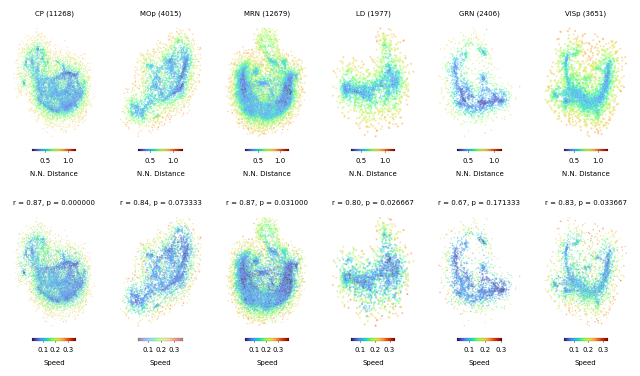

In [101]:
fig = plt.figure(figsize=(8, 4))
gs = gridspec.GridSpec(2, 6,hspace = .6)

# First row
ax1 = plt.subplot(gs[0,0])
ax2 = plt.subplot(gs[0,1])
ax3 = plt.subplot(gs[0,2])
ax4 = plt.subplot(gs[0,3])
ax5 = plt.subplot(gs[0,4])
ax6 = plt.subplot(gs[0,5])
# Second row
ax12 = plt.subplot(gs[1,0])
ax22 = plt.subplot(gs[1,1])
ax32 = plt.subplot(gs[1,2])
ax42 = plt.subplot(gs[1,3])
ax52 = plt.subplot(gs[1,4])
ax62 = plt.subplot(gs[1,5])

# CP
vmax = np.max(density_CP)+.3
sns.scatterplot(x=z_neurons_CP[:, 0], y=z_neurons_CP[:, 1], c=density_CP,cmap  = 'turbo', s=.5, alpha=.5,ax=ax1,vmax=vmax)
cax = inset_axes(
        ax1, width="50%", height="2%",
        loc="lower center", borderpad=-1
    )
norm = plt.Normalize(density_CP.min(), density_CP.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("N.N. Distance", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)
vmax = np.max(msd_CP)+.05
sns.scatterplot(x=z_neurons_CP[:, 0], y=z_neurons_CP[:, 1], c=msd_CP,cmap  = 'turbo', s=.5, alpha=.5,ax=ax12,vmax=vmax)
cax = inset_axes(
        ax12, width="50%", height="2%",
        loc="lower center", borderpad=-1
    )
norm = plt.Normalize(msd_CP.min(), msd_CP.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("Speed", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)
ax1.set_title(f"CP ({X_CP.shape[0]})"   ,fontsize=5)
ax12.set_title(f"r = {r_CP:.2f}" + f", p = {p_CP:.6f}"   ,fontsize=5)


# MOp
vmax = np.max(density_MOp)+.3
sns.scatterplot(x=z_neurons_MOp[:, 0], y=z_neurons_MOp[:, 1], c=density_MOp,cmap  = 'turbo', s=1, alpha=.5,ax=ax2,vmax=vmax)
cax = inset_axes(
        ax2, width="50%", height="2%",
        loc="lower center", borderpad=-1
    )
norm = plt.Normalize(density_MOp.min(), density_MOp.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("N.N. Distance", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)

vmax = np.max(msd_MOp)+.05
sns.scatterplot(x=z_neurons_MOp[:, 0], y=z_neurons_MOp[:, 1], c=msd_MOp,cmap  = 'turbo', s=1, alpha=.5,ax=ax22,vmax=vmax)
cax = inset_axes(
        ax22, width="50%", height="2%",
        loc="lower center", borderpad=-1
    )
norm = plt.Normalize(msd_MOp.min(), msd_MOp.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal",alpha=.5)
cb.outline.set_linewidth(0.1)
cax.set_xlabel("Speed", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)
ax2.set_title(f"MOp ({X_MOp.shape[0]})"   ,fontsize=5)
ax22.set_title(f"r = {r_MOp:.2f}" + f", p = {p_MOp:.6f}"  ,fontsize=5)
# MRN
vmax = np.max(density_MRN)+.3
sns.scatterplot(x=z_neurons_MRN[:, 0], y=z_neurons_MRN[:, 1], c=density_MRN,cmap  = 'turbo', s=1, alpha=.5,ax=ax3,vmax=vmax)
cax = inset_axes(
        ax3, width="50%", height="2%",
        loc="lower center", borderpad=-1
    )
norm = plt.Normalize(density_MRN.min(), density_MRN.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("N.N. Distance", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)

vmax = np.max(msd_MRN)+.05
sns.scatterplot(x=z_neurons_MRN[:, 0], y=z_neurons_MRN[:, 1], c=msd_MRN,cmap  = 'turbo', s=1, alpha=.5,ax=ax32,vmax=vmax)
cax = inset_axes(
        ax32, width="50%", height="2%",
        loc="lower center", borderpad=-1
    )
norm = plt.Normalize(msd_MRN.min(), msd_MRN.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("Speed", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)
ax3.set_title(f"MRN ({X_MRN.shape[0]})"   ,fontsize=5)
ax32.set_title(f"r = {r_MRN:.2f}" + f", p = {p_MRN:.6f}"  ,fontsize=5)


# LD
vmax = np.max(density_LD)+.3
sns.scatterplot(x=z_neurons_LD[:, 0], y=z_neurons_LD[:, 1], c=density_LD,cmap  = 'turbo', s=2, alpha=.5,ax=ax4,vmax=vmax)
cax = inset_axes(
        ax4, width="50%", height="2%",
        loc="lower center", borderpad=-1
    )
norm = plt.Normalize(density_LD.min(), density_LD.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("N.N. Distance", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)

vmax = np.max(msd_LD)+.05
sns.scatterplot(x=z_neurons_LD[:, 0], y=z_neurons_LD[:, 1], c=msd_LD,cmap  = 'turbo', s=2, alpha=.5,ax=ax42,vmax=vmax)
cax = inset_axes(
        ax42, width="50%", height="2%",
        loc="lower center", borderpad=-1
    )
norm = plt.Normalize(msd_LD.min(), msd_LD.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("Speed", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)
ax4.set_title("LD",fontsize=6)
ax4.set_title(f"LD ({X_LD.shape[0]})"   ,fontsize=5)
ax42.set_title(f"r = {r_LD:.2f}"+ f", p = {p_LD:.6f}"   ,fontsize=5)
# GRN
vmax = np.max(density_GRN)+.3
sns.scatterplot(x=z_neurons_GRN[:, 0], y=z_neurons_GRN[:, 1], c=density_GRN,cmap  = 'turbo', s=1, alpha=.5,ax=ax5,vmax=vmax)
cax = inset_axes(
        ax5, width="50%", height="2%",
        loc="lower center", borderpad=-1
    )
norm = plt.Normalize(density_GRN.min(), density_GRN.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("N.N. Distance", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)

vmax = np.max(msd_GRN)+.05
sns.scatterplot(x=z_neurons_GRN[:, 0], y=z_neurons_GRN[:, 1], c=msd_GRN,cmap  = 'turbo', s=1, alpha=.5,ax=ax52,vmax=vmax)
cax = inset_axes(
        ax52, width="50%", height="2%",
        loc="lower center", borderpad=-1
    )
norm = plt.Normalize(msd_GRN.min(), msd_GRN.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("Speed", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)
ax5.set_title("GRN",fontsize=6)
ax5.set_title(f"GRN ({X_GRN.shape[0]})"   ,fontsize=5)
ax52.set_title(f"r = {r_GRN:.2f}" + f", p = {p_GRN:.6f}"  ,fontsize=5)

# VISp
vmax = np.max(density_VISp)+.3
sns.scatterplot(x=z_neurons_VISp[:, 0], y=z_neurons_VISp[:, 1], c=density_VISp,cmap  = 'turbo', s=2, alpha=.5,ax=ax6,vmax=vmax)
cax = inset_axes(
        ax6, width="50%", height="2%",
        loc="lower center", borderpad=-1
    )
norm = plt.Normalize(density_VISp.min(), density_VISp.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("N.N. Distance", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)

vmax = np.max(msd_VISp)+.05
sns.scatterplot(x=z_neurons_VISp[:, 0], y=z_neurons_VISp[:, 1], c=msd_VISp,cmap  = 'turbo', s=1, alpha=.5,ax=ax62,vmax=vmax)
cax = inset_axes(
        ax62, width="50%", height="2%",
        loc="lower center", borderpad=-1
    )
norm = plt.Normalize(msd_VISp.min(), msd_VISp.max())
sm = plt.cm.ScalarMappable(cmap="turbo", norm=norm)
cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
cb.outline.set_linewidth(0.1)
cax.set_xlabel("Speed", fontsize=5, labelpad=5)
cax.xaxis.set_tick_params(size=1, width=.5, color="black")
cax.xaxis.set_tick_params(labelsize=5)
ax6.set_title(f"VISp ({X_VISp.shape[0]})"   ,fontsize=5)
ax62.set_title(f"r = {r_VISp:.2f}"  + f", p = {p_VISp:.6f}" ,fontsize=5)


for ax in [ax1,ax2,ax3,ax4,ax5,ax6,ax12,ax22,ax32,ax42,ax52,ax62]:
    for spine in ax.spines.values():
        spine.set_visible(False)

    # 2. Hide the tick marks and tick numbers
    ax.set_xticks([])
    ax.set_yticks([])

    # 3. Add your labels normally
    ax.set_xlabel('')
    ax.set_ylabel('')

plt.savefig('berylexamples.png', dpi=300, bbox_inches='tight')
